# Predictive Modeling

## Goal

Compare several approaches for predicting municipal voter turnout:

1. Historical-turnout baseline
2. Linear Regression
3. Decision Tree
4. Random Forest

The models are evaluated using temporal validation rather than a random
train/test split.

Historical validation:

- Train on 2014 → predict 2018
- Train on 2014 + 2018 → predict 2022

Final prospective model:

- Train on 2014 + 2018 + 2022 → predict 2026

In [ ]:
# Data handling
import pandas as pd
import numpy as np

# File paths
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt

# Machine-learning models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# Load the cleaned historical dataset from the processed-data folder.
# municipality_code is kept as a string because it is an identifier.

master_df = pd.read_csv(
    "../data/processed/master_model_dataset_2014_2022.csv",
    dtype={"municipality_code": str}
)

master_df.shape

(870, 12)

In [ ]:
# Training data:
# only observations from the 2014 election

train_2014 = master_df[
    master_df["election_year"] == 2014
].copy()


# Test data:
# only observations from the 2018 election

test_2018 = master_df[
    master_df["election_year"] == 2018
].copy()

In [ ]:
train_2014.shape

(290, 12)

In [ ]:
test_2018.shape

(290, 12)

In [ ]:
# Historical-turnout baseline:
#
# Predict the 2018 turnout simply by using the municipality's
# turnout from the previous election (2014).

y_true_2018 = test_2018["turnout_pct"]

y_pred_baseline_2018 = test_2018["previous_turnout_pct"]

In [ ]:
# Calculate Mean Absolute Error (MAE)
#
# y_true_2018 contains the actual 2018 turnout values.
# y_pred_baseline_2018 contains our baseline predictions,
# which are simply the 2014 turnout values.
#
# MAE measures the average absolute difference between
# actual and predicted turnout.

mae_baseline_2018 = mean_absolute_error(
    y_true_2018,
    y_pred_baseline_2018
)

print("Baseline MAE:", round(mae_baseline_2018, 3))

Baseline MAE: 1.339


In [ ]:
# Calculate Mean Squared Error (MSE)
#
# The difference between actual and predicted turnout
# is squared, so large errors receive a larger penalty.

mse_baseline_2018 = mean_squared_error(
    y_true_2018,
    y_pred_baseline_2018
)

# RMSE is the square root of MSE.
# Taking the square root brings the result back
# to the original unit: percentage points.

rmse_baseline_2018 = np.sqrt(mse_baseline_2018)

print("Baseline RMSE:", round(rmse_baseline_2018, 3))

Baseline RMSE: 1.473


In [ ]:
# Calculate R-squared for the 2018 baseline predictions.
#
# R-squared compares our predictions with a simple reference:
# predicting the mean turnout of the test set for every municipality.
#
# Higher R-squared is better.
# R-squared = 1 means perfect predictions.
# R-squared = 0 means the model performs about as well as predicting the mean.
# R-squared can also be negative if the predictions are worse than the mean baseline.

r2_baseline_2018 = r2_score(
    y_true_2018,
    y_pred_baseline_2018
)

print("Baseline R²:", round(r2_baseline_2018, 3))

Baseline R²: 0.664


In [ ]:
# Features that will be available before an election.
#
# municipality_code and municipality_name are NOT included
# because they are identifiers, not predictors.
#
# election_year is also excluded because our goal is genuine
# future-election forecasting.

features = [
    "previous_turnout_pct",
    "median_income_ksek",
    "registered_unemployed_pct",
    "higher_education_pct",
    "average_age",
    "log_population_density"
]

In [ ]:
# X contains predictor variables.
# y contains the value we want to predict: turnout.

X_train_2014 = train_2014[features]
y_train_2014 = train_2014["turnout_pct"]

X_test_2018 = test_2018[features]
y_test_2018 = test_2018["turnout_pct"]

In [ ]:
# Create a linear regression model.
linear_2018 = LinearRegression()

# Learn the relationship between the predictors
# and turnout using ONLY the 2014 election.
linear_2018.fit(
    X_train_2014,
    y_train_2014
)

# Use the learned 2014 relationships to predict
# turnout for municipalities in the 2018 election.
y_pred_linear_2018 = linear_2018.predict(
    X_test_2018
)

In [ ]:
# Calculate MAE for the Linear Regression model.
# This tells us the average absolute prediction error
# across the 290 municipalities.

mae_linear_2018 = mean_absolute_error(
    y_test_2018,
    y_pred_linear_2018
)


# Calculate RMSE.
# RMSE penalizes large prediction errors more heavily than MAE.

rmse_linear_2018 = np.sqrt(
    mean_squared_error(
        y_test_2018,
        y_pred_linear_2018
    )
)


# Calculate predictive R-squared.
# Higher R² means the model captures more of the
# municipality-to-municipality variation in 2018 turnout.

r2_linear_2018 = r2_score(
    y_test_2018,
    y_pred_linear_2018
)


print("Linear Regression MAE:", round(mae_linear_2018, 3))
print("Linear Regression RMSE:", round(rmse_linear_2018, 3))
print("Linear Regression R²:", round(r2_linear_2018, 3))

Linear Regression MAE: 0.593
Linear Regression RMSE: 0.785
Linear Regression R²: 0.904


## Temporal Validation 2: Predicting the 2022 Election

The second validation experiment uses all available earlier elections
for training:

Training data:
- 2014
- 2018

Test data:
- 2022

The 2022 election is kept completely unseen during model training.

In [ ]:
# Create the training dataset containing only elections
# that occurred before 2022.
#
# This gives us 290 municipalities × 2 elections = 580 rows.

train_2014_2018 = master_df[
    master_df["election_year"].isin([2014, 2018])
].copy()


# Create the unseen 2022 test dataset.
# It contains 290 municipality observations.

test_2022 = master_df[
    master_df["election_year"] == 2022
].copy()


# Separate predictors (X) and target turnout (y)
# for the training data.

X_train_2022 = train_2014_2018[features]
y_train_2022 = train_2014_2018["turnout_pct"]


# Predictor values for the unseen 2022 election.

X_test_2022 = test_2022[features]


# Actual 2022 turnout.
# This is used only AFTER prediction to evaluate accuracy.

y_test_2022 = test_2022["turnout_pct"]

In [ ]:
print("Training shape:", X_train_2022.shape)
print("Test shape:", X_test_2022.shape)

Training shape: (580, 6)
Test shape: (290, 6)


### Historical-Turnout Baseline - 2022

As a benchmark, 2022 turnout is predicted using each municipality's
turnout in the previous Riksdag election (2018).

This baseline requires no model training and provides a reference for
evaluating the learned models.

In [ ]:
# ============================================================
# 2022 HISTORICAL-TURNOUT BASELINE
# ============================================================

# Use each municipality's 2018 turnout as its prediction for 2022.
y_pred_baseline_2022 = test_2022["previous_turnout_pct"]

# Evaluate the baseline.
mae_baseline_2022 = mean_absolute_error(
    y_test_2022,
    y_pred_baseline_2022
)

rmse_baseline_2022 = np.sqrt(
    mean_squared_error(
        y_test_2022,
        y_pred_baseline_2022
    )
)

r2_baseline_2022 = r2_score(
    y_test_2022,
    y_pred_baseline_2022
)

print("2022 Baseline MAE:", round(mae_baseline_2022, 3))
print("2022 Baseline RMSE:", round(rmse_baseline_2022, 3))
print("2022 Baseline R²:", round(r2_baseline_2022, 3))

2022 Baseline MAE: 2.34
2022 Baseline RMSE: 2.589
2022 Baseline R²: 0.299


In [ ]:
# Create a new Linear Regression model.
# We use a new model object because this is a separate
# temporal validation experiment.

linear_2022 = LinearRegression()


# Learn the relationship between predictors and turnout
# using both the 2014 and 2018 elections.

linear_2022.fit(
    X_train_2022,
    y_train_2022
)


# Apply the learned model to the unseen 2022 predictor data.

y_pred_linear_2022 = linear_2022.predict(
    X_test_2022
)

In [ ]:
# Mean Absolute Error
mae_linear_2022 = mean_absolute_error(
    y_test_2022,
    y_pred_linear_2022
)


# Root Mean Squared Error
rmse_linear_2022 = np.sqrt(
    mean_squared_error(
        y_test_2022,
        y_pred_linear_2022
    )
)


# Predictive R-squared
r2_linear_2022 = r2_score(
    y_test_2022,
    y_pred_linear_2022
)


print("2022 Linear Regression MAE:", round(mae_linear_2022, 3))
print("2022 Linear Regression RMSE:", round(rmse_linear_2022, 3))
print("2022 Linear Regression R²:", round(r2_linear_2022, 3))

2022 Linear Regression MAE: 3.564
2022 Linear Regression RMSE: 3.718
2022 Linear Regression R²: -0.446


In [ ]:
# Compare the average actual 2022 turnout
# with the average turnout predicted by Linear Regression.

print(
    "Actual 2022 mean:",
    round(y_test_2022.mean(), 3)
)

print(
    "Predicted 2022 mean:",
    round(y_pred_linear_2022.mean(), 3)
)


# Calculate prediction bias.
#
# Positive bias:
# predictions are too high on average.
#
# Negative bias:
# predictions are too low on average.

prediction_bias_2022 = np.mean(
    y_pred_linear_2022 - y_test_2022
)

print(
    "Mean prediction bias:",
    round(prediction_bias_2022, 3)
)

Actual 2022 mean: 84.84
Predicted 2022 mean: 88.404
Mean prediction bias: 3.564


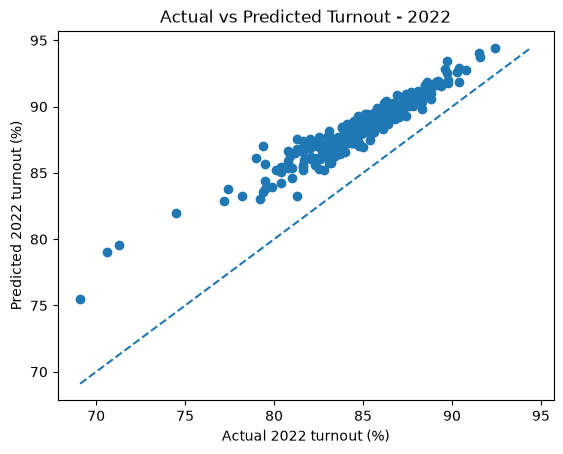

In [ ]:
# Compare actual 2022 turnout with Linear Regression predictions.

plt.scatter(
    y_test_2022,
    y_pred_linear_2022
)

# Perfect-prediction reference line.
# A point on this line means predicted turnout = actual turnout.

minimum = min(
    y_test_2022.min(),
    y_pred_linear_2022.min()
)

maximum = max(
    y_test_2022.max(),
    y_pred_linear_2022.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual 2022 turnout (%)")
plt.ylabel("Predicted 2022 turnout (%)")
plt.title("Actual vs Predicted Turnout - 2022")
plt.show()

In [ ]:
# Calculate prediction errors:
# positive error means the model predicted turnout too high.
prediction_errors_2022 = (
    y_pred_linear_2022 - y_test_2022
)

# Count how many municipalities were overpredicted
number_overpredicted = (
    prediction_errors_2022 > 0
).sum()

# Count how many municipalities were underpredicted
number_underpredicted = (
    prediction_errors_2022 < 0
).sum()

print("Overpredicted municipalities:", number_overpredicted)
print("Underpredicted municipalities:", number_underpredicted)

# Check the smallest and largest prediction errors
print("Minimum prediction error:", round(prediction_errors_2022.min(), 3))
print("Maximum prediction error:", round(prediction_errors_2022.max(), 3))

Overpredicted municipalities: 290
Underpredicted municipalities: 0
Minimum prediction error: 1.49
Maximum prediction error: 8.415


In [ ]:
# Correlation tells us whether municipalities predicted
# to have high turnout also tended to actually have high turnout.
correlation_2022 = np.corrcoef(
    y_test_2022,
    y_pred_linear_2022
)[0, 1]

print(
    "Actual-predicted correlation:",
    round(correlation_2022, 3)
)

Actual-predicted correlation: 0.961


### Diagnosis of 2022 Linear Regression Performance

The model overpredicted turnout for all 290 municipalities in 2022.
The mean prediction bias was +3.564 percentage points.

Despite this systematic overprediction, the correlation between actual
and predicted turnout was very high (r = 0.961). This indicates that the
model captured the relative ordering of municipalities well but failed
to predict the overall level of turnout in 2022.

Therefore, the poor predictive R² was primarily associated with
systematic calibration error rather than failure to distinguish
high-turnout from low-turnout municipalities.

## Decision Tree Regression

Linear Regression assumes that turnout can be predicted using one linear
combination of the input features.

A Decision Tree uses a different approach. Instead of fitting one equation,
it repeatedly splits the data into groups using rules based on predictor values.

Conceptually, the tree may learn rules such as:

- Is previous turnout below a certain value?
- If yes, is unemployment high or low?
- If no, is higher education above a certain threshold?

This allows the model to capture nonlinear relationships and interactions
between predictors.

### Why control tree complexity?

A Decision Tree can easily overfit the training data by creating too many
splits and memorizing individual observations.

To reduce this risk:

- `max_depth=4` limits how deep the tree can grow.
- `min_samples_leaf=10` requires each final leaf to contain at least
  10 training observations.
- `random_state=42` makes the result reproducible.

### Temporal Validation

First experiment:

- Train on the 2014 election
- Predict the unseen 2018 election

The Decision Tree will be compared with:

1. Historical-turnout baseline
2. Linear Regression

using:

- MAE
- RMSE
- R²

In [ ]:
# Create a Decision Tree regression model.
#
# max_depth=4 limits how many levels the tree can grow.
# This reduces the risk of memorizing the training data.
#
# min_samples_leaf=10 means that every final leaf must
# contain at least 10 training observations.
#
# random_state=42 makes the result reproducible.

tree_2018 = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)


# Learn decision rules using only the 2014 election.
tree_2018.fit(
    X_train_2014,
    y_train_2014
)


# Apply the learned rules to the unseen 2018 predictors.
y_pred_tree_2018 = tree_2018.predict(
    X_test_2018
)

In [ ]:
# Mean Absolute Error
mae_tree_2018 = mean_absolute_error(
    y_test_2018,
    y_pred_tree_2018
)


# Root Mean Squared Error
rmse_tree_2018 = np.sqrt(
    mean_squared_error(
        y_test_2018,
        y_pred_tree_2018
    )
)


# Predictive R-squared
r2_tree_2018 = r2_score(
    y_test_2018,
    y_pred_tree_2018
)


print("Decision Tree MAE:", round(mae_tree_2018, 3))
print("Decision Tree RMSE:", round(rmse_tree_2018, 3))
print("Decision Tree R²:", round(r2_tree_2018, 3))

Decision Tree MAE: 0.71
Decision Tree RMSE: 0.999
Decision Tree R²: 0.845


### Decision Tree Results - 2018

The Decision Tree substantially outperformed the historical-turnout baseline.

Its MAE was 0.710 percentage points compared with 1.339 for the baseline,
and its predictive R² was 0.845 compared with 0.664 for the baseline.

However, Linear Regression performed better than the Decision Tree on all
three evaluation metrics.

This suggests that the relationships learned from the 2014 election may be
captured effectively by a relatively simple linear model, while the additional
flexibility of the Decision Tree did not improve out-of-election prediction.

In [ ]:
# Create a Decision Tree for the second temporal validation experiment.
#
# The same complexity controls are used so that the comparison
# with the 2018 experiment remains fair.

tree_2022 = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)


# Train the tree using only elections before 2022:
# 2014 and 2018.

tree_2022.fit(
    X_train_2022,
    y_train_2022
)


# Predict turnout for the unseen 2022 election.

y_pred_tree_2022 = tree_2022.predict(
    X_test_2022
)

In [ ]:
# Calculate MAE
mae_tree_2022 = mean_absolute_error(
    y_test_2022,
    y_pred_tree_2022
)


# Calculate RMSE
rmse_tree_2022 = np.sqrt(
    mean_squared_error(
        y_test_2022,
        y_pred_tree_2022
    )
)


# Calculate predictive R-squared
r2_tree_2022 = r2_score(
    y_test_2022,
    y_pred_tree_2022
)


print("2022 Decision Tree MAE:", round(mae_tree_2022, 3))
print("2022 Decision Tree RMSE:", round(rmse_tree_2022, 3))
print("2022 Decision Tree R²:", round(r2_tree_2022, 3))

2022 Decision Tree MAE: 3.554
2022 Decision Tree RMSE: 3.764
2022 Decision Tree R²: -0.482


### Decision Tree Results - 2022

The Decision Tree did not generalize well to the 2022 election.

Its MAE was 3.554 percentage points and its predictive R² was -0.482.
Performance was therefore substantially worse than the historical-turnout
baseline, which achieved an MAE of 2.340 and an R² of 0.299.

The Decision Tree performed similarly to Linear Regression, suggesting that
the poor 2022 prediction was not simply caused by the linearity assumption.

Instead, the results are consistent with a temporal shift in turnout that
was not captured by the municipality-level predictors learned from the
2014 and 2018 elections.

## Random Forest Regression

A Random Forest combines predictions from many Decision Trees.

Each tree learns slightly different patterns from the training data, and
their predictions are averaged to produce the final turnout prediction.

Compared with a single Decision Tree, Random Forest can:

- reduce sensitivity to individual training observations,
- model nonlinear relationships,
- capture interactions between predictors,
- and often generalize more reliably.

The Random Forest is evaluated using the same temporal validation strategy
as the previous models.

In [ ]:
# Create a Random Forest regression model.
#
# n_estimators=500:
# build 500 individual Decision Trees.
#
# max_depth=6:
# limits the complexity of each tree.
#
# min_samples_leaf=5:
# each final leaf must contain at least 5 training observations.
#
# random_state=42:
# makes the results reproducible.
#
# n_jobs=-1:
# uses all available CPU cores to train the trees faster.

rf_2018 = RandomForestRegressor(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)


# Train the Random Forest using only 2014 data.
rf_2018.fit(
    X_train_2014,
    y_train_2014
)


# Predict the unseen 2018 election.
y_pred_rf_2018 = rf_2018.predict(
    X_test_2018
)

In [ ]:
# Calculate MAE
mae_rf_2018 = mean_absolute_error(
    y_test_2018,
    y_pred_rf_2018
)


# Calculate RMSE
rmse_rf_2018 = np.sqrt(
    mean_squared_error(
        y_test_2018,
        y_pred_rf_2018
    )
)


# Calculate predictive R-squared
r2_rf_2018 = r2_score(
    y_test_2018,
    y_pred_rf_2018
)


print("Random Forest MAE:", round(mae_rf_2018, 3))
print("Random Forest RMSE:", round(rmse_rf_2018, 3))
print("Random Forest R²:", round(r2_rf_2018, 3))

Random Forest MAE: 0.583
Random Forest RMSE: 0.859
Random Forest R²: 0.886


### Random Forest Results - 2018

Random Forest achieved an MAE of 0.583 percentage points,
an RMSE of 0.859, and a predictive R² of 0.886.

It achieved the lowest MAE among the tested models, slightly outperforming
Linear Regression on average absolute error.

However, Linear Regression achieved a lower RMSE and a higher predictive R².
Therefore, neither model dominated across all evaluation metrics.

Both models substantially outperformed the historical-turnout baseline.

In [ ]:
# Create a Random Forest for the 2022 temporal validation experiment.
#
# We keep the same hyperparameters as the 2018 experiment
# so that we do not change the model after seeing test results.

rf_2022 = RandomForestRegressor(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train using only elections before 2022:
# 2014 and 2018.
rf_2022.fit(
    X_train_2022,
    y_train_2022
)

# Predict the unseen 2022 election.
y_pred_rf_2022 = rf_2022.predict(
    X_test_2022
)

In [ ]:
# Calculate MAE
mae_rf_2022 = mean_absolute_error(
    y_test_2022,
    y_pred_rf_2022
)

# Calculate RMSE
rmse_rf_2022 = np.sqrt(
    mean_squared_error(
        y_test_2022,
        y_pred_rf_2022
    )
)

# Calculate predictive R-squared
r2_rf_2022 = r2_score(
    y_test_2022,
    y_pred_rf_2022
)

print("2022 Random Forest MAE:", round(mae_rf_2022, 3))
print("2022 Random Forest RMSE:", round(rmse_rf_2022, 3))
print("2022 Random Forest R²:", round(r2_rf_2022, 3))

2022 Random Forest MAE: 3.491
2022 Random Forest RMSE: 3.69
2022 Random Forest R²: -0.425


### Random Forest Results - 2022

Random Forest achieved an MAE of 3.491 percentage points,
an RMSE of 3.690, and a predictive R² of -0.425.

Although Random Forest performed slightly better than Linear Regression
and the single Decision Tree on some metrics, it still performed
substantially worse than the historical-turnout baseline.

Because Linear Regression, Decision Tree, and Random Forest all struggled
to predict the 2022 election, increasing model flexibility did not solve
the generalization problem.

The results are therefore consistent with an election-wide temporal shift
in turnout that was not captured by the municipality-level socioeconomic
and demographic predictors available from earlier elections.

In [ ]:
# Calculate the Random Forest prediction errors for 2022.
#
# Positive error:
# predicted turnout > actual turnout
# Therefore, the model overpredicted.
#
# Negative error:
# predicted turnout < actual turnout
# Therefore, the model underpredicted.

rf_errors_2022 = (
    y_pred_rf_2022 - y_test_2022
)


# Calculate the average prediction bias.
# A positive value means systematic overprediction.

rf_bias_2022 = rf_errors_2022.mean()


# Count the number of municipalities that were
# overpredicted and underpredicted.

rf_overpredicted = (
    rf_errors_2022 > 0
).sum()

rf_underpredicted = (
    rf_errors_2022 < 0
).sum()


# Compare the actual and predicted average turnout.

print(
    "Actual 2022 mean:",
    round(y_test_2022.mean(), 3)
)

print(
    "Random Forest predicted mean:",
    round(y_pred_rf_2022.mean(), 3)
)

print(
    "Random Forest mean bias:",
    round(rf_bias_2022, 3)
)

print(
    "Overpredicted municipalities:",
    rf_overpredicted
)

print(
    "Underpredicted municipalities:",
    rf_underpredicted
)

Actual 2022 mean: 84.84
Random Forest predicted mean: 88.331
Random Forest mean bias: 3.491
Overpredicted municipalities: 290
Underpredicted municipalities: 0


### Diagnosis of Random Forest Performance in 2022

Random Forest systematically overpredicted voter turnout in the 2022 election.

The actual mean municipal turnout was 84.840%, while the predicted mean was
88.331%, corresponding to an average positive prediction bias of 3.491
percentage points.

All 290 municipalities were overpredicted.

Because Linear Regression and Random Forest both showed a similar systematic
upward prediction bias, the 2022 forecasting problem does not appear to be
explained simply by model linearity.

Instead, the results are consistent with an election-wide temporal shift that
was not represented by the municipality-level socioeconomic and demographic
predictors learned from earlier elections.

In [ ]:
# Create a single table containing the predictive performance
# of every model for both temporal validation elections.
#
# This makes it easy to compare:
# - models within the same election
# - performance changes between 2018 and 2022

results = pd.DataFrame({

    "election": [
        2018, 2018, 2018, 2018,
        2022, 2022, 2022, 2022
    ],

    "model": [
        "Historical Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Historical Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "MAE": [
        mae_baseline_2018,
        mae_linear_2018,
        mae_tree_2018,
        mae_rf_2018,
        mae_baseline_2022,
        mae_linear_2022,
        mae_tree_2022,
        mae_rf_2022
    ],

    "RMSE": [
        rmse_baseline_2018,
        rmse_linear_2018,
        rmse_tree_2018,
        rmse_rf_2018,
        rmse_baseline_2022,
        rmse_linear_2022,
        rmse_tree_2022,
        rmse_rf_2022
    ],

    "R2": [
        r2_baseline_2018,
        r2_linear_2018,
        r2_tree_2018,
        r2_rf_2018,
        r2_baseline_2022,
        r2_linear_2022,
        r2_tree_2022,
        r2_rf_2022
    ]
})

# Round the metrics so the table is easier to read.
results.round(3)

,election,model,MAE,RMSE,R2
0,2018,Historical Baseline,1.339,1.473,0.664
1,2018,Linear Regression,0.593,0.785,0.904
2,2018,Decision Tree,0.710,0.999,0.845
3,2018,Random Forest,0.583,0.859,0.886
4,2022,Historical Baseline,2.340,2.589,0.299
5,2022,Linear Regression,3.564,3.718,-0.446
6,2022,Decision Tree,3.554,3.764,-0.482
7,2022,Random Forest,3.491,3.690,-0.425


In [ ]:
results.head()

,election,model,MAE,RMSE,R2
0,2018,Historical Baseline,1.338966,1.472565,0.663837
1,2018,Linear Regression,0.593239,0.785416,0.904369
2,2018,Decision Tree,0.710228,0.998625,0.845402
3,2018,Random Forest,0.583009,0.858991,0.885613
4,2022,Historical Baseline,2.340000,2.588689,0.298914


## Temporal Validation Summary and Implications for the 2026 Forecast

The historical validation results showed that model performance was not stable
across election cycles.

### Model Performance

| Election | Model | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| 2018 | Historical Baseline | 1.339 | 1.473 | 0.664 |
| 2018 | Linear Regression | 0.593 | 0.785 | 0.904 |
| 2018 | Decision Tree | 0.710 | 0.999 | 0.845 |
| 2018 | Random Forest | 0.583 | 0.859 | 0.886 |
| 2022 | Historical Baseline | 2.340 | 2.589 | 0.299 |
| 2022 | Linear Regression | 3.564 | 3.718 | -0.446 |
| 2022 | Decision Tree | 3.554 | 3.764 | -0.482 |
| 2022 | Random Forest | 3.491 | 3.690 | -0.425 |

### Interpretation

For the 2018 election, all three learned models substantially outperformed the
historical-turnout baseline. Random Forest achieved the lowest MAE, while
Linear Regression achieved the lowest RMSE and highest predictive R².

However, the results changed substantially when predicting the 2022 election.
The historical-turnout baseline outperformed Linear Regression, Decision Tree,
and Random Forest on all three evaluation metrics.

This demonstrates that strong predictive performance in one election does not
guarantee equally strong performance in a later election.

### Evidence of Temporal Shift in 2022

Further analysis showed that the poor 2022 performance was largely caused by
systematic overprediction rather than an inability to distinguish high-turnout
and low-turnout municipalities.

For example, Linear Regression produced:

- Actual mean turnout in 2022: 84.840%
- Predicted mean turnout: 88.404%
- Mean prediction bias: +3.564 percentage points
- Overpredicted municipalities: 290 out of 290
- Actual-predicted correlation: 0.961

Random Forest showed a very similar pattern:

- Actual mean turnout: 84.840%
- Predicted mean turnout: 88.331%
- Mean prediction bias: +3.491 percentage points
- Overpredicted municipalities: 290 out of 290

The high correlation between predicted and actual turnout indicates that the
models captured relative differences between municipalities well, but failed
to anticipate the overall decline in turnout in the 2022 election.

Therefore, the 2022 prediction problem appears to be more consistent with an
election-wide temporal shift than simply with an incorrect assumption of
linearity.

### Main Finding from Historical Validation

The historical validation suggests that municipality-level socioeconomic and
demographic predictors can substantially improve turnout prediction in some
election cycles, as observed for 2018.

However, these predictive gains are not stable across elections.

Historical turnout therefore remains an important and relatively robust
benchmark, particularly when the overall electoral environment changes.

The results also demonstrate why temporal validation is necessary. A model
selected only on the basis of its strong 2018 performance would have appeared
highly successful, but its poor performance in 2022 reveals important limits to
out-of-election generalization.

### Implication for the 2026 Forecast

Because no single model consistently dominated across the historical validation
elections, the 2026 analysis will not rely on only one forecasting method.

Instead, separate prospective predictions will be generated using:

1. Historical-turnout baseline
2. Linear Regression
3. Decision Tree
4. Random Forest

All available historical elections (2014, 2018, and 2022) will be used for
training where applicable.

The 2026 predictions will be generated using only information available before
the election and should be saved before the actual 2026 turnout results are
known.

This allows the 2026 election to serve as a genuine prospective evaluation of
the competing forecasting approaches.

## Prospective Forecast for the 2026 Riksdag Election

The final forecasting models are trained using all available historical
municipality-election observations from the 2014, 2018, and 2022 elections.

The 2026 prediction dataset contains:

- turnout in the previous election (2022), and
- socioeconomic and demographic predictors measured in 2024.

No 2026 turnout information is used.

Four forecasting approaches are retained because historical validation showed
that no single model consistently performed best across election cycles:

1. Historical-turnout baseline
2. Linear Regression
3. Decision Tree Regression
4. Random Forest Regression

The same predictor definitions and model settings used during historical
validation are retained for the prospective forecast.

In [ ]:
# Load the completed 2026 feature dataset created
# in the data-preparation notebook.

forecast_2026 = pd.read_csv(
    "../data/processed/forecast_features_2026.csv",
    dtype={"municipality_code": str}
)

forecast_2026.head()

,municipality_code,municipality_name,previous_turnout_pct,election_year,predictor_year,median_income_ksek,registered_unemployed_pct,higher_education_pct,average_age,population_density,log_population_density
0,0114,Upplands Väsby,79.5,2026,2024,525.3,13.4,46.650718,39.9,667.6,6.503689
1,0115,Vallentuna,87.4,2026,2024,647.3,8.0,52.457162,40.4,97.7,4.581902
2,0117,Österåker,87.3,2026,2024,668.2,8.0,50.757916,41.4,158.6,5.066385
3,0120,Värmdö,88.4,2026,2024,642.6,7.9,50.606139,42.0,104.4,4.648230
4,0123,Järfälla,79.4,2026,2024,523.9,14.0,51.965445,39.3,1645.4,7.405739


In [ ]:
# ============================================================
# CHECK THE 2026 FORECAST DATA
# ============================================================

# Check dataset dimensions.
print("Historical dataset shape:", master_df.shape)
print("2026 forecast dataset shape:", forecast_2026.shape)


# Check that all modelling predictors exist in both datasets.
missing_historical = [
    col for col in features
    if col not in master_df.columns
]

missing_2026 = [
    col for col in features
    if col not in forecast_2026.columns
]

print("\nMissing predictors from historical data:", missing_historical)
print("Missing predictors from 2026 data:", missing_2026)


# Confirm the historical election years.
print("\nHistorical observations by election:")
print(
    master_df["election_year"]
    .value_counts()
    .sort_index()
)


# Confirm that the prospective dataset represents:
# predictor year = 2024
# forecast election = 2026
print("\n2026 predictor years:")
print(
    forecast_2026["predictor_year"]
    .value_counts()
)

print("\nForecast election years:")
print(
    forecast_2026["election_year"]
    .value_counts()
)


# Final integrity checks.
assert master_df.shape == (870, 12)
assert forecast_2026.shape == (290, 11)

assert forecast_2026["municipality_code"].nunique() == 290
assert forecast_2026["municipality_code"].duplicated().sum() == 0
assert forecast_2026.isna().sum().sum() == 0

assert set(forecast_2026["predictor_year"]) == {2024}
assert set(forecast_2026["election_year"]) == {2026}

assert missing_historical == []
assert missing_2026 == []

print("\nAll forecast-data checks passed.")

Historical dataset shape: (870, 12)
2026 forecast dataset shape: (290, 11)

Missing predictors from historical data: []
Missing predictors from 2026 data: []

Historical observations by election:
election_year
2014    290
2018    290
2022    290
Name: count, dtype: int64

2026 predictor years:
predictor_year
2024    290
Name: count, dtype: int64

Forecast election years:
election_year
2026    290
Name: count, dtype: int64

All forecast-data checks passed.


In [ ]:
# X = predictor variables for historical elections
X_train_final = master_df[features]

# y = turnout that actually occurred in 2014, 2018 and 2022
y_train_final = master_df["turnout_pct"]

# X values for the election we want to forecast
X_2026 = forecast_2026[features]


print("X historical:", X_train_final.shape)
print("y historical:", y_train_final.shape)
print("X 2026:", X_2026.shape)

X historical: (870, 6)
y historical: (870,)
X 2026: (290, 6)


### Forecast Training Setup

The final models use **870 historical municipality-election observations**
and six pre-election predictors.

Each model is then applied to the same six predictor variables for the
290 municipalities in the 2026 forecast dataset.

The 2026 election year itself is not used as a predictive feature.

## Final Models for the 2026 Forecast

The final forecasting models are trained using all available historical
observations from the 2014, 2018 and 2022 elections.

This gives:

- 870 historical municipality-election observations
- 6 predictor variables
- 290 municipalities to forecast for 2026

The same model specifications used during historical temporal validation
are retained. This avoids changing model settings after examining the
historical validation results.

Four forecasting approaches are used:

1. Historical-turnout baseline
2. Linear Regression
3. Decision Tree
4. Random Forest

The historical baseline does not require model training. It assumes that
each municipality's 2026 turnout will equal its turnout in 2022.

In [ ]:
# ============================================================
# HISTORICAL-TURNOUT BASELINE
# ============================================================

# The baseline assumes that turnout in 2026 will be
# exactly the same as turnout in the previous election (2022).

pred_baseline_2026 = forecast_2026["previous_turnout_pct"].copy()

print(
    "Baseline predictions:",
    pred_baseline_2026.shape
)

Baseline predictions: (290,)


In [ ]:
# ============================================================
# LINEAR REGRESSION
# ============================================================

# Create the model.
linear_final = LinearRegression()


# Train it using all historical observations:
# 2014 + 2018 + 2022.
linear_final.fit(
    X_train_final,
    y_train_final
)


# Apply the learned model to the 2026 predictor data.
pred_linear_2026 = linear_final.predict(
    X_2026
)


print(
    "Linear Regression predictions:",
    pred_linear_2026.shape
)

Linear Regression predictions: (290,)


In [ ]:
# ============================================================
# DECISION TREE
# ============================================================

tree_final = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)


# Train on all historical elections.
tree_final.fit(
    X_train_final,
    y_train_final
)


# Predict 2026 turnout.
pred_tree_2026 = tree_final.predict(
    X_2026
)


print(
    "Decision Tree predictions:",
    pred_tree_2026.shape
)

Decision Tree predictions: (290,)


In [ ]:
# ============================================================
# RANDOM FOREST
# ============================================================

rf_final = RandomForestRegressor(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)


# Train using 2014 + 2018 + 2022.
rf_final.fit(
    X_train_final,
    y_train_final
)


# Predict the unseen 2026 election.
pred_rf_2026 = rf_final.predict(
    X_2026
)


print(
    "Random Forest predictions:",
    pred_rf_2026.shape
)

Random Forest predictions: (290,)


In [ ]:
# ============================================================
# CREATE FINAL 2026 FORECAST TABLE
# ============================================================

# Start with municipality identifiers and 2022 turnout.

predictions_2026 = forecast_2026[
    [
        "municipality_code",
        "municipality_name",
        "previous_turnout_pct"
    ]
].copy()


# Add the four prospective forecasts.

predictions_2026["baseline_prediction"] = (
    pred_baseline_2026
)

predictions_2026["linear_regression_prediction"] = (
    pred_linear_2026
)

predictions_2026["decision_tree_prediction"] = (
    pred_tree_2026
)

predictions_2026["random_forest_prediction"] = (
    pred_rf_2026
)


predictions_2026.head(10)

,municipality_code,municipality_name,previous_turnout_pct,baseline_prediction,linear_regression_prediction,decision_tree_prediction,random_forest_prediction
0,0114,Upplands Väsby,79.5,79.5,81.203981,80.372727,80.300126
1,0115,Vallentuna,87.4,87.4,87.237989,89.947619,89.168827
2,0117,Österåker,87.3,87.3,87.045843,89.947619,89.207286
3,0120,Värmdö,88.4,88.4,87.963506,89.947619,89.601141
4,0123,Järfälla,79.4,79.4,80.917239,80.372727,79.788386
5,0125,Ekerö,90.4,90.4,88.994191,91.609524,91.551725
6,0126,Huddinge,80.8,80.8,82.111081,80.838462,80.908000
7,0127,Botkyrka,71.3,71.3,74.804051,75.230000,75.601840
8,0128,Salem,85.0,85.0,85.263637,85.329870,85.413396
9,0136,Haninge,79.0,79.0,81.195746,80.372727,79.867666


In [ ]:
# Define the columns containing the four prospective forecasts.

prediction_columns = [
    "baseline_prediction",
    "linear_regression_prediction",
    "decision_tree_prediction",
    "random_forest_prediction"
]


# Check for missing predictions.

print("Missing predictions:")

print(
    predictions_2026[
        prediction_columns
    ].isna().sum()
)


# Confirm that every municipality received one prediction
# from each forecasting approach.

assert predictions_2026.shape[0] == 290

assert (
    predictions_2026[
        prediction_columns
    ].isna().sum().sum()
    == 0
)


# Turnout is expressed as a percentage, so predictions should
# fall within the logically possible range from 0 to 100.

assert (
    predictions_2026[
        prediction_columns
    ]
    .ge(0)
    .all()
    .all()
)

assert (
    predictions_2026[
        prediction_columns
    ]
    .le(100)
    .all()
    .all()
)

print("\nAll prediction checks passed.")

Missing predictions:
baseline_prediction             0
linear_regression_prediction    0
decision_tree_prediction        0
random_forest_prediction        0
dtype: int64

All prediction checks passed.


In [ ]:
# Summary statistics for the four forecasts.

predictions_2026[
    prediction_columns
].describe().round(3)

,baseline_prediction,linear_regression_prediction,decision_tree_prediction,random_forest_prediction
count,290.000,290.000,290.000,290.000
mean,84.840,85.926,86.032,86.052
std,3.097,2.413,3.026,2.933
min,69.100,74.391,75.230,75.334
25%,83.200,84.786,84.102,84.577
50%,85.050,86.174,85.330,86.134
75%,86.800,87.439,87.320,87.796
max,92.400,90.720,91.610,91.880


### Preliminary Forecast Comparison

The three fitted models predict a higher mean municipal turnout in 2026 than
the historical-turnout baseline.

The Linear Regression predictions have the smallest spread across
municipalities, while the Decision Tree and Random Forest preserve somewhat
more cross-municipality variation.

These values represent the **mean and distribution of municipality-level
predictions**. They should not be interpreted as predictions of Sweden's
population-weighted national turnout.

In [ ]:
print(
    "2022 municipality mean turnout:",
    round(
        forecast_2026["previous_turnout_pct"].mean(),
        3
    )
)

print(
    "2026 Baseline mean:",
    round(
        pred_baseline_2026.mean(),
        3
    )
)

print(
    "2026 Linear Regression mean:",
    round(
        pred_linear_2026.mean(),
        3
    )
)

print(
    "2026 Decision Tree mean:",
    round(
        pred_tree_2026.mean(),
        3
    )
)

print(
    "2026 Random Forest mean:",
    round(
        pred_rf_2026.mean(),
        3
    )
)

2022 municipality mean turnout: 84.84
2026 Baseline mean: 84.84
2026 Linear Regression mean: 85.926
2026 Decision Tree mean: 86.032
2026 Random Forest mean: 86.052


## Freeze the Prospective 2026 Predictions

The following municipality-level forecasts were generated prospectively,
before the 2026 Riksdag election outcome was used in the analysis.

The forecasts are saved in a dated file so that the original predictions can
be evaluated against the observed 2026 turnout after the election.

The frozen forecast should not be modified after observing the 2026 election
results. Any subsequent model changes should be saved separately and clearly
identified as exploratory or post-election analyses.

In [ ]:
# ============================================================
# FREEZE THE PROSPECTIVE 2026 FORECAST
# ============================================================

# Create the results folder if it does not already exist.

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)


# Add metadata documenting the forecast.
#
# 2026-09-09 is retained as the original forecast-generation date.
# Cleaning or rerunning the notebook later should not change this date.

predictions_2026["election_year"] = 2026
predictions_2026["forecast_generated_on"] = "2026-09-09"


# Arrange columns in a clear reporting order.

predictions_2026 = predictions_2026[
    [
        "municipality_code",
        "municipality_name",
        "election_year",
        "forecast_generated_on",
        "previous_turnout_pct",
        "baseline_prediction",
        "linear_regression_prediction",
        "decision_tree_prediction",
        "random_forest_prediction"
    ]
]


# Define the path of the frozen prospective forecast.

frozen_path = (
    results_dir
    / "turnout_predictions_2026_frozen_2026-09-09.csv"
)


# Protect the frozen forecast from accidental overwriting.
#
# If the file already exists, verify that the current predictions
# are identical to the previously saved forecasts.
#
# If they are different, the notebook will stop rather than
# overwrite the original prospective forecast.

if frozen_path.exists():

    existing_frozen = pd.read_csv(
        frozen_path,
        dtype={"municipality_code": str}
    )

    pd.testing.assert_frame_equal(
        existing_frozen.reset_index(drop=True),
        predictions_2026.reset_index(drop=True),
        check_dtype=False,
        rtol=1e-10,
        atol=1e-10
    )

    print(
        "Frozen 2026 forecast already exists "
        "and matches the current predictions."
    )

    print(
        "Existing frozen file preserved:",
        frozen_path
    )

else:

    predictions_2026.to_csv(
        frozen_path,
        index=False
    )

    print(
        "Frozen 2026 forecast saved:",
        frozen_path
    )


print("Forecast table shape:", predictions_2026.shape)

Frozen 2026 forecast already exists and matches the current predictions.
Existing frozen file preserved: ..\results\turnout_predictions_2026_frozen_2026-09-09.csv
Forecast table shape: (290, 9)


In [ ]:
# ============================================================
# SAVE HISTORICAL TEMPORAL-VALIDATION RESULTS
# ============================================================

validation_path = (
    results_dir
    / "historical_model_validation.csv"
)


results.to_csv(
    validation_path,
    index=False
)


print(
    "Historical validation results saved:",
    validation_path
)

results.round(3)

Historical validation results saved:

 ..\results\historical_model_validation.csv


,election,model,MAE,RMSE,R2
0,2018,Historical Baseline,1.339,1.473,0.664
1,2018,Linear Regression,0.593,0.785,0.904
2,2018,Decision Tree,0.710,0.999,0.845
3,2018,Random Forest,0.583,0.859,0.886
4,2022,Historical Baseline,2.340,2.589,0.299
5,2022,Linear Regression,3.564,3.718,-0.446
6,2022,Decision Tree,3.554,3.764,-0.482
7,2022,Random Forest,3.491,3.690,-0.425


## 2026 Forecast Summary

The municipality-level predictions are summarized to compare the overall
forecast distributions produced by the four approaches.

The mean prediction is compared with the mean municipal turnout observed in
2022. These values are unweighted averages across the 290 municipalities and
should not be interpreted as predictions of Sweden's population-weighted
national turnout.

In [ ]:
# ============================================================
# CREATE 2026 FORECAST SUMMARY
# ============================================================

# Mean municipality-level turnout in the 2022 election.
mean_2022 = forecast_2026["previous_turnout_pct"].mean()


# Create a compact summary of the four prospective forecasts.
forecast_summary = pd.DataFrame({
    "model": [
        "Historical Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "mean_2026_prediction": [
        pred_baseline_2026.mean(),
        pred_linear_2026.mean(),
        pred_tree_2026.mean(),
        pred_rf_2026.mean()
    ]
})


# Calculate how much each model predicts turnout will
# change relative to the 2022 mean municipal turnout.
forecast_summary["change_vs_2022_pp"] = (
    forecast_summary["mean_2026_prediction"]
    - mean_2022
)


forecast_summary.round(3)

,model,mean_2026_prediction,change_vs_2022_pp
0,Historical Baseline,84.840,0.000
1,Linear Regression,85.926,1.086
2,Decision Tree,86.032,1.192
3,Random Forest,86.052,1.212


### Interpretation

The historical-turnout baseline predicts no change from the 2022 municipal
turnout distribution by construction.

The three fitted models predict a modest increase in mean municipal turnout
for 2026. Their mean predictions are relatively similar, ranging from
approximately **85.93% to 86.05%**, corresponding to increases of about
**1.09 to 1.21 percentage points** relative to the 2022 municipal mean.

These are averages of municipality-level forecasts and are not predictions
of population-weighted national voter turnout.

In [ ]:
# Save the compact summary of the prospective 2026 forecasts.

summary_path = (
    results_dir
    / "forecast_summary_2026.csv"
)


forecast_summary.to_csv(
    summary_path,
    index=False
)


print(
    "2026 forecast summary saved:",
    summary_path
)

2026 forecast summary saved: ..\results\forecast_summary_2026.csv


## Predictive Modelling Summary

Historical temporal validation showed that forecasting performance varied
substantially between elections. Linear Regression and Random Forest performed
strongly when predicting 2018, while the simple historical-turnout baseline
performed best when predicting 2022.

The 2022 results demonstrate that strong relationships learned from earlier
elections do not necessarily transfer unchanged to a later election,
particularly when an election-wide shift in turnout occurs.

Because no model was consistently superior across the historical validation
periods, all four pre-specified forecasting approaches were retained for the
prospective 2026 election forecast.

The original 2026 municipality-level predictions have been saved as a dated
frozen forecast so that they can later be evaluated against the observed 2026
election results without modifying the prospective predictions.